In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load and inspect
print("--- Loading Data ---")
df_raw = pd.read_csv('sales_raw.csv')

print(f"Shape: {df_raw.shape}")
print("\nColumns:", df_raw.columns.tolist())
print("\nData Types:\n", df_raw.dtypes)

print("\nFirst 5 rows:")
display(df_raw.head())

print("\nMissing values:\n", df_raw.isna().sum())
print(f"\nDuplicate rows: {df_raw.duplicated().sum()}")

# Save original row count for comparison
original_row_count = df_raw.shape[0]

--- Loading Data ---
Shape: (21, 6)

Columns: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']

Data Types:
 transaction_id      int64
sale_date             str
region                str
category              str
quantity          float64
unit_price            str
dtype: object

First 5 rows:


,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250



Missing values:
 transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

Duplicate rows: 1


In [5]:
# Create a copy for cleaning to preserve original input CSV
df_clean = df_raw.copy()

# Trim extra spaces and standardize text
if 'region' in df_clean.columns:
    df_clean['region'] = df_clean['region'].astype(str).str.strip().str.title()
if 'category' in df_clean.columns:
    df_clean['category'] = df_clean['category'].astype(str).str.strip().str.title()

# Handle missing values: drop rows where critical columns are missing
df_clean.dropna(subset=['transaction_id', 'unit_price', 'quantity'], inplace=True)

# ---> FIX: Convert columns to numeric types first (forces errors to NaN) <---
df_clean['unit_price'] = pd.to_numeric(df_clean['unit_price'], errors='coerce')
df_clean['quantity'] = pd.to_numeric(df_clean['quantity'], errors='coerce')

# Drop any rows that became NaN during the conversion
df_clean.dropna(subset=['unit_price', 'quantity'], inplace=True)

# Handle invalid prices/quantities: keep only rows where price and quantity are > 0
df_clean = df_clean[(df_clean['unit_price'] > 0) & (df_clean['quantity'] > 0)]

# Remove duplicates
df_clean.drop_duplicates(inplace=True)

# Compare row counts
print(f"Rows before cleaning: {original_row_count}")
print(f"Rows after cleaning: {df_clean.shape[0]}")

Rows before cleaning: 21
Rows after cleaning: 16


C:\Users\admin\AppData\Local\Temp\ipykernel_14132\2475316131.py:11: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.dropna(subset=['transaction_id', 'unit_price', 'quantity'], inplace=True)
C:\Users\admin\AppData\Local\Temp\ipykernel_14132\2475316131.py:18: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.dropna(subset=['unit_price', 'quantity'], inplace=True)
C:\Users\admin\AppData\Local\Temp\ipykernel_14132\2475316131.py:24: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace


Revenue by Category:
      category  revenue
0       Books   2370.0
1        Food   1945.0
2  Stationery  10460.0


C:\Users\admin\AppData\Local\Temp\ipykernel_14132\869399243.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=revenue_by_category, x='category', y='revenue', palette='viridis')


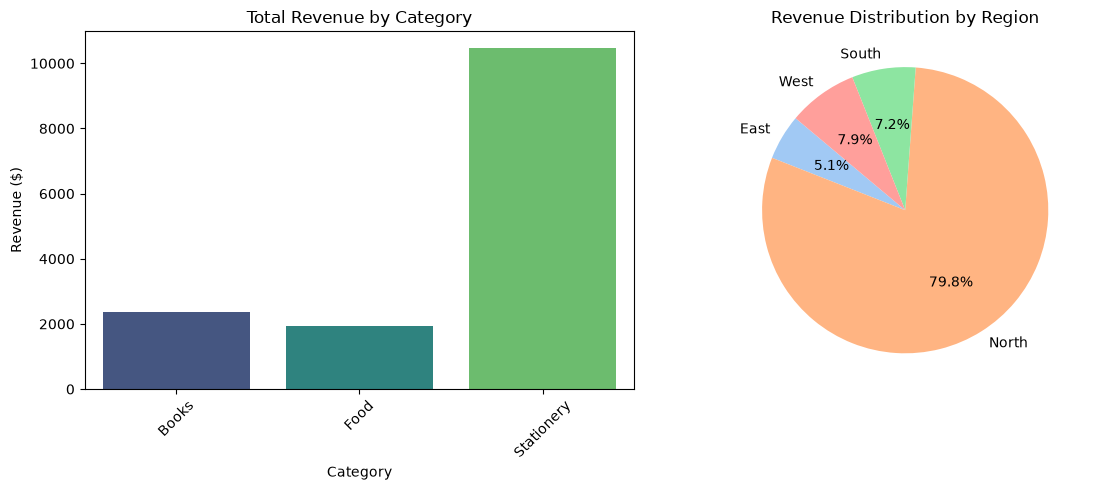

In [6]:
# Add revenue column[cite: 1]
df_clean['revenue'] = df_clean['quantity'] * df_clean['unit_price']

# Summarize revenue by category[cite: 1]
revenue_by_category = df_clean.groupby('category')['revenue'].sum().reset_index()
revenue_by_region = df_clean.groupby('region')['revenue'].sum().reset_index()
print("\nRevenue by Category:\n", revenue_by_category)

# Create two labelled charts[cite: 1]
plt.figure(figsize=(12, 5))

# Chart 1: Bar Chart of Revenue by Category
plt.subplot(1, 2, 1)
sns.barplot(data=revenue_by_category, x='category', y='revenue', palette='viridis')
plt.title('Total Revenue by Category')
plt.xlabel('Category')
plt.ylabel('Revenue ($)')
plt.xticks(rotation=45)

# Chart 2: Pie Chart of Revenue by Region
plt.subplot(1, 2, 2)
plt.pie(revenue_by_region['revenue'], labels=revenue_by_region['region'], autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Revenue Distribution by Region')

plt.tight_layout()
plt.show()

# Findings[cite: 1]: 
# 1. Provide an observation from the bar chart (e.g., "Category X generates the highest revenue.")
# 2. Provide an observation from the pie chart (e.g., "Region Y accounts for Z% of total sales.")

In [7]:
# Export cleaned dataset[cite: 1]
df_clean.to_csv('cleaned_sales.csv', index=False)
print("Part A Complete: 'cleaned_sales.csv' saved.")

Part A Complete: 'cleaned_sales.csv' saved.


In [8]:
# 1. Read cleaned data
df_part_b = pd.read_csv('cleaned_sales.csv')

# Add tax_amount (5% of revenue)
df_part_b['tax_amount'] = df_part_b['revenue'] * 0.05

print("First 5 rows after adding tax_amount:")
display(df_part_b.head())

First 5 rows after adding tax_amount:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,10/1/2026,North,Food,2.0,120.0,240.0,12.0
1,1002,10/1/2026,South,Books,1.0,250.0,250.0,12.5
2,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.5
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.0
4,1005,10/3/2026,South,Books,2.0,250.0,500.0,25.0


In [9]:
# 2. Update unit_price for 'Books' by 10%
book_condition = df_part_b['category'] == 'Books'
df_part_b.loc[book_condition, 'unit_price'] = df_part_b.loc[book_condition, 'unit_price'] * 1.10

# Recalculate revenue and tax_amount for the updated rows[cite: 2]
df_part_b.loc[book_condition, 'revenue'] = df_part_b.loc[book_condition, 'quantity'] * df_part_b.loc[book_condition, 'unit_price']
df_part_b.loc[book_condition, 'tax_amount'] = df_part_b.loc[book_condition, 'revenue'] * 0.05

# Remove one selected row using an existing transaction_id (replace 'TXN-001' with an actual ID from your data)[cite: 2]
sample_txn_id = df_part_b['transaction_id'].iloc[0] 
df_part_b = df_part_b[df_part_b['transaction_id'] != sample_txn_id]

# Create a temporary review_status column, then remove it[cite: 2]
df_part_b['review_status'] = 'Pending'
df_part_b = df_part_b.drop(columns=['review_status'])

In [10]:
# 3. Save to sales_updated.csv[cite: 2]
df_part_b.to_csv('sales_updated.csv', index=False)

# Read it again and verify[cite: 2]
df_final = pd.read_csv('sales_updated.csv')
print("\nFinal column names:\n", df_final.columns.tolist())
print("\nFirst 5 rows of final dataset:")
display(df_final.head())


Final column names:
 ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']

First 5 rows of final dataset:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1002,10/1/2026,South,Books,1.0,275.0,275.0,13.75
1,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.50
2,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.00
3,1005,10/3/2026,South,Books,2.0,275.0,550.0,27.50
4,1007,10/4/2026,North,Stationery,3.0,60.0,180.0,9.00
